In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla

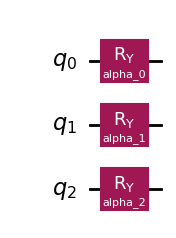

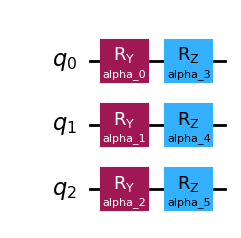

In [2]:
vqls_rz = oasis_dla.VQLS(qubits=3, ansatz_type=1)
vqls_ry = oasis_dla.VQLS(qubits=3, ansatz_type=0)

display(vqls_ry.ansatz.draw('mpl'))
display(vqls_rz.ansatz.draw('mpl'))
# display(vqls_rz.construct_controlled_ansatz().draw('mpl'))

In [3]:
A_0 = np.eye(8) # 2^3
A_1 = 0.2 * np.kron(np.kron(oasis_dla.X, oasis_dla.Z), np.eye(2))
A_2 = 0.2 * np.kron(np.kron(oasis_dla.X, np.eye(2)), np.eye(2))
A = A_0 + A_1 + A_2

b = np.ones(8) / np.sqrt(8)

res = vqls_ry.solve(A, b)
q_soln = res.solution()
c_soln = np.linalg.solve(A, b).reshape(-1, 1)

Solving
Optimizing
Training time: 1.1295705000084126
 message: The maximum number of iterations has been exceeded
 success: False
  status: 6
     fun: 0.038266629970294064
       x: [ 1.109e+00  1.822e+00  9.488e-01]
     nit: 1
   maxcv: 0.0
    nfev: 8
Readout


In [4]:
print(f"Quantum Soln: \n{q_soln}")
print(f"Classical Soln: \n{c_soln}")

acc = vqls_ry.compute_accuracy(q_soln, c_soln)
print(f"Accuracy: {acc}")

Quantum Soln: 
[[0.40575508+0.j]
 [0.25142784+0.j]
 [0.52320867+0.j]
 [0.32420845+0.j]
 [0.20836939+0.j]
 [0.12911697+0.j]
 [0.26868591+0.j]
 [0.16649235+0.j]]
Classical Soln: 
[[0.25253814+0.j]
 [0.25253814+0.j]
 [0.35355339+0.j]
 [0.35355339+0.j]
 [0.25253814+0.j]
 [0.25253814+0.j]
 [0.35355339+0.j]
 [0.35355339+0.j]]
Accuracy: 0.6645917596587672


In [5]:
res

Scaled Solution: 
[[0.40575508+0.j]
 [0.25142784+0.j]
 [0.52320867+0.j]
 [0.32420845+0.j]
 [0.20836939+0.j]
 [0.12911697+0.j]
 [0.26868591+0.j]
 [0.16649235+0.j]]

In [6]:
prob_list = []
for i in range(0, 5):
    res = vqls_ry.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

Solving
Optimizing
Training time: 1.165057300007902
 message: The maximum number of iterations has been exceeded
 success: False
  status: 6
     fun: 0.09001334971122604
       x: [ 1.912e+00  9.560e-01  5.549e-01]
     nit: 1
   maxcv: 0.0
    nfev: 8
Readout
Solving
Optimizing
Training time: 1.0289982000103919
 message: The maximum number of iterations has been exceeded
 success: False
  status: 6
     fun: 0.022818569347898998
       x: [ 1.269e+00  2.052e+00  1.120e+00]
     nit: 1
   maxcv: 0.0
    nfev: 8
Readout
Solving
Optimizing
Training time: 0.993397800004459
 message: The maximum number of iterations has been exceeded
 success: False
  status: 6
     fun: 0.060742782473659385
       x: [ 1.916e+00  1.122e+00  9.670e-01]
     nit: 1
   maxcv: 0.0
    nfev: 8
Readout
Solving
Optimizing
Training time: 1.385394599987194
 message: The maximum number of iterations has been exceeded
 success: False
  status: 6
     fun: 0.02722042651526646
       x: [ 1.254e+00  2.012e+00  1.037e

classical probabilities: [0.08445946 0.08445946 0.16554054 0.16554054 0.08445946 0.08445946
 0.16554054 0.16554054]


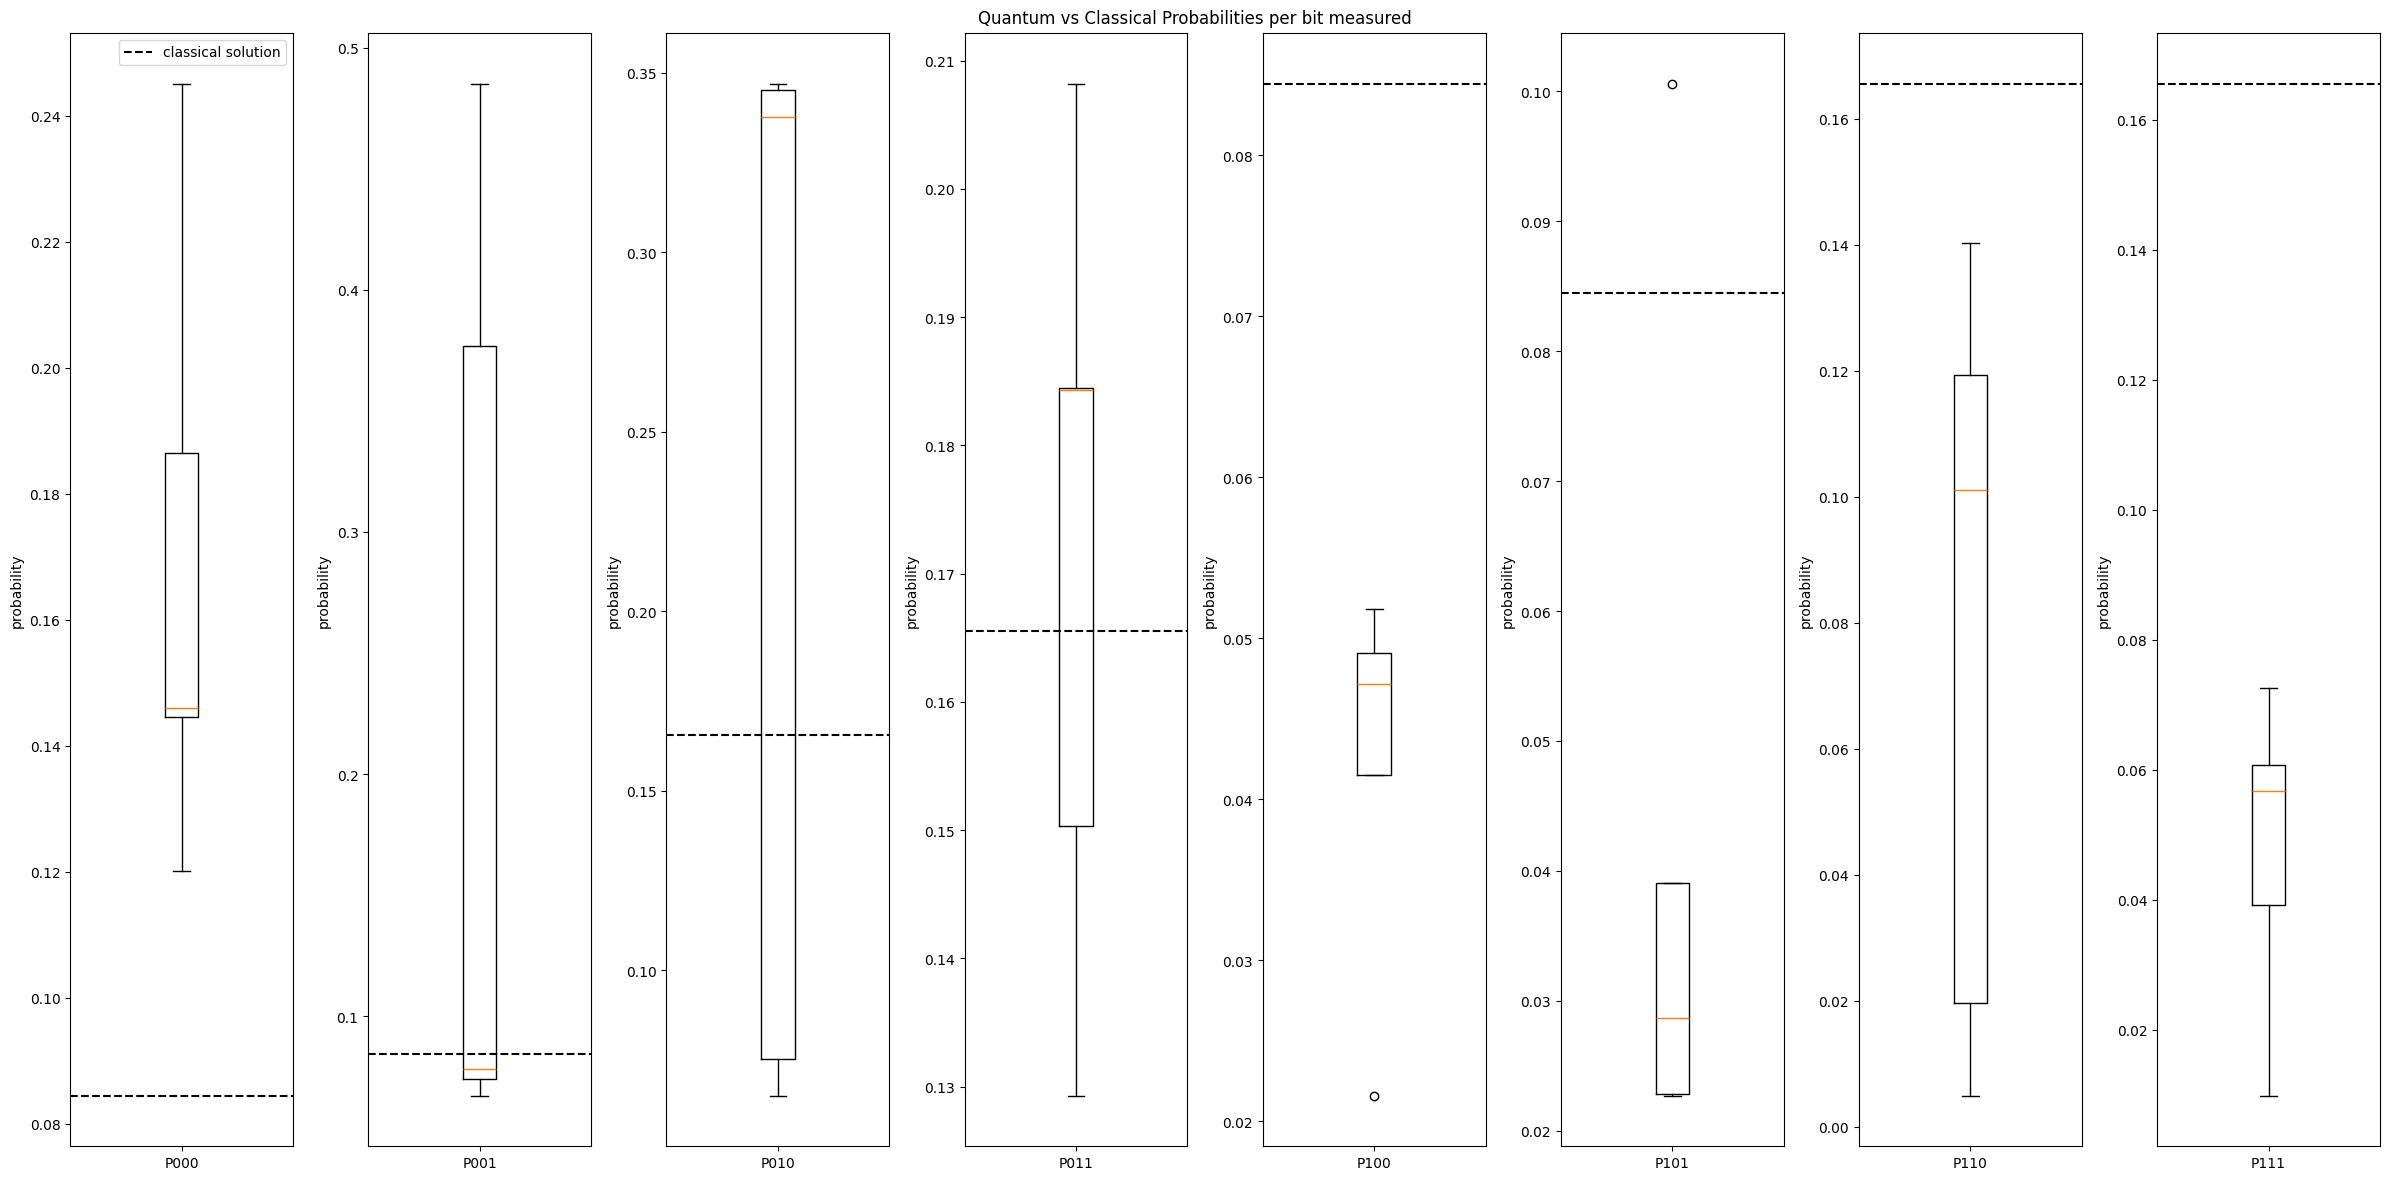

In [7]:
# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

p_quantum = [
    [probs.get(bitstr, 0) for probs in prob_list] for bitstr in [f"{x:03b}" for x in range(0, 8)]
]

p_quantum

fig, axes = plt.subplots(1, 8, figsize=(24, 12))
for ax, data, p_true, label in zip(axes, [*p_quantum], p_classical, [f"P{x:03b}" for x in range(0, 8)]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
fig.suptitle("Quantum vs Classical Probabilities per bit measured")
plt.tight_layout()
plt.show()